# 06 · Validación fuera de muestra

En este notebook se pone a prueba la política con lo que realmente ocurrió en 2026. Se simula que la fundación empieza con USD 100 000 a finales de diciembre de 2025 y, trimestre a trimestre, invierte según la política estocástica: al cerrar cada trimestre se observa si cada activo subió o bajó, se ubica el nodo del árbol que corresponde a esa historia y se aplican sus proporciones a la riqueza que realmente hay. Lo mismo se hace, por separado y con su propia riqueza, con la estrategia simple del modelo de valor esperado. Al final se compara cuánto acumuló cada una en septiembre de 2026 y si alcanzó la meta. Este es el único notebook que abre los datos de 2026, y lo hace solo después de comprobar que las dos estrategias siguen exactamente como se guardaron. Nada del modelo se reestima ni se vuelve a optimizar con esa información.

In [1]:
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 170)
ASSET_COLORS = {"SPY": "#1f77b4", "LQD": "#2ca02c", "GLD": "#d4a017"}

## 1. Verificación de las políticas congeladas (antes de leer 2026)

Se comprueba que los parámetros, el árbol, la política estocástica y la regla EV no cambiaron desde que se guardaron. Solo si todo coincide se continúa a la lectura de los precios de validación.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PARAMS_DIR = ROOT / "results" / "parameters"
TREE_DIR = ROOT / "results" / "tree"
POLICY_DIR = ROOT / "results" / "policy"
VAL_OUT = ROOT / "results" / "validation"
FIGURES_DIR = ROOT / "results" / "figures"
for d in [VAL_OUT, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

params_path = PARAMS_DIR / "calibration_parameters.json"
params_hash = (PARAMS_DIR / "calibration_parameters.sha256").read_text().strip()
assert sha256_of(params_path) == params_hash, "Los parámetros congelados cambiaron."
params = json.loads(params_path.read_text(encoding="utf-8"))

tree_meta = json.loads((TREE_DIR / "tree_metadata.json").read_text(encoding="utf-8"))
assert sha256_of(ROOT / tree_meta["csv_file"]) == tree_meta["csv_sha256"], "El árbol cambió."
tree = pd.read_csv(ROOT / tree_meta["csv_file"], keep_default_na=False, na_values=[""])

sp_meta_path = POLICY_DIR / "lshaped_policy.json"
assert sha256_of(sp_meta_path) == (POLICY_DIR / "lshaped_policy.sha256").read_text().strip(), \
    "La política estocástica cambió después de congelarse."
sp_meta = json.loads(sp_meta_path.read_text(encoding="utf-8"))
assert sha256_of(ROOT / sp_meta["policy_csv"]) == sp_meta["policy_csv_sha256"]
assert sp_meta["calibration_parameters_sha256"] == params_hash

ev_path = POLICY_DIR / "ev_policy.json"
assert sha256_of(ev_path) == (POLICY_DIR / "ev_policy.sha256").read_text().strip(), \
    "La regla EV cambió después de congelarse."
ev_meta = json.loads(ev_path.read_text(encoding="utf-8"))
assert ev_meta["calibration_parameters_sha256"] == params_hash

policy = pd.read_csv(ROOT / sp_meta["policy_csv"], keep_default_na=False, na_values=[""])

TICKERS = params["tickers"]
B_CAP, M_GOAL, LAM = params["b"], params["M"], params["lambda"]
ACTIVE_STATES = params["active_states"]
REMOVED_STATES = params["removed_states"]
R_HAT = {u: np.array([params["states"][u]["R_hat"][t] for t in TICKERS]) for u in ACTIVE_STATES}
H = int(tree["t"].max())
GOAL_TOL = 1e-6          # misma tolerancia monetaria declarada en el notebook 05 (miles de USD)

F_BY_NODE = {(r.t, r.k): np.array([getattr(r, f"f_{tk}") for tk in TICKERS]) for r in policy.itertuples()}
V_TREE = {(r.t, r.k): float(sum(getattr(r, f"x_{tk}") for tk in TICKERS)) for r in policy.itertuples()}
G_EV = {int(t): np.array([ev_meta["g"][t][tk] for tk in TICKERS]) for t in ev_meta["g"]}
HIST_TO_K = {(t, h): k for t, h, k in zip(tree["t"], tree["history"], tree["k"])}

verified_at = datetime.now(timezone.utc)
print("✔ Parámetros, árbol, política estocástica y regla EV verificados.")
print(f"  Política estocástica congelada: {sp_meta['frozen_at_utc']}  (RP = {sp_meta['RP_expected_cost']:.6f})")
print(f"  Regla EV congelada:             {ev_meta['frozen_at_utc']}  (EEV = {ev_meta['EEV']:.6f})")
print(f"  Verificación realizada:         {verified_at.isoformat(timespec='seconds')}")
print("Regla de aplicación:", sp_meta["application_rule"])

✔ Parámetros, árbol, política estocástica y regla EV verificados.
  Política estocástica congelada: 2026-10-16T13:32:51+00:00  (RP = 1.271199)
  Regla EV congelada:             2026-10-16T13:32:58+00:00  (EEV = 2.753228)
  Verificación realizada:         2026-10-16T13:33:02+00:00
Regla de aplicación: Extensión por proporciones (sección 5.2): la terna de signos observada (SPY, LQD, GLD; B si r < 0, A si r ≥ 0) determina la historia y el nodo; las proporciones f de ese nodo se aplican a la riqueza realmente disponible. La riqueza se actualiza con los factores reales. No se reestiman parámetros ni se reoptimiza con datos de 2026.


## 2. Lectura de los precios de validación y factores reales 

Se leen los cuatro cierres ajustados $\tilde P_{i,0}$ (diciembre de 2025) y $\tilde P_{i,1}, \tilde P_{i,2}, \tilde P_{i,3}$ (marzo, junio y septiembre de 2026) guardados por el notebook 00, verificando su hash. Los factores reales son $\tilde R_{i,\tau} = \tilde P_{i,\tau}/\tilde P_{i,\tau-1}$ y la terna $\tilde z_\tau$ asigna B si $\tilde r_{i,\tau} < 0$ y A en otro caso, en el orden SPY, LQD, GLD.

In [3]:
val_meta = json.loads((ROOT / "data" / "validation" / "metadata.json").read_text(encoding="utf-8"))
val_csv = ROOT / val_meta["csv_file"]
assert sha256_of(val_csv) == val_meta["csv_sha256"], "El CSV de validación cambió desde el notebook 00."
val = pd.read_csv(val_csv, dtype={"quarter": str, "date": str})
assert val["quarter"].tolist() == ["2025Q4", "2026Q1", "2026Q2", "2026Q3"] and val["tau"].tolist() == [0, 1, 2, 3]

P_val = val[TICKERS].to_numpy(dtype=float)
R_REAL = {tau: P_val[tau] / P_val[tau - 1] for tau in (1, 2, 3)}
r_REAL = {tau: R_REAL[tau] - 1 for tau in (1, 2, 3)}
Z_REAL = {tau: "".join("B" if v < 0 else "A" for v in r_REAL[tau]) for tau in (1, 2, 3)}
DATES = val["date"].tolist()
QLABEL = {1: "ene–mar 2026", 2: "abr–jun 2026", 3: "jul–sep 2026"}

obs = pd.DataFrame([{"trimestre τ": tau, "período": QLABEL[tau], "inicio": DATES[tau - 1], "fin": DATES[tau],
                     **{f"r̃ {tk} (%)": 100 * r_REAL[tau][i] for i, tk in enumerate(TICKERS)},
                     **{f"R̃ {tk}": R_REAL[tau][i] for i, tk in enumerate(TICKERS)},
                     "terna z̃": Z_REAL[tau]} for tau in (1, 2, 3)]).set_index("trimestre τ")
print(f"Validación: {val_csv.relative_to(ROOT)} (consulta {val_meta['consulted_at_bogota']}, hash verificado)")
with pd.option_context("display.float_format", "{:.6f}".format):
    display(obs)

Validación: data/validation/quarterly_adjclose_2025_2026.csv (consulta 2026-10-04T16:26:16-05:00, hash verificado)


,período,inicio,fin,r̃ SPY (%),r̃ LQD (%),r̃ GLD (%),R̃ SPY,R̃ LQD,R̃ GLD,terna z̃
trimestre τ,,,,,,,,,,
1,ene–mar 2026,2025-12-31,2026-03-31,-4.370589,-0.381063,8.574099,0.956294,0.996189,1.085741,BBA
2,abr–jun 2026,2026-03-31,2026-06-30,15.123457,1.260879,-14.387971,1.151235,1.012609,0.856120,AAB
3,jul–sep 2026,2026-06-30,2026-09-30,2.377406,-5.184414,3.382375,1.023774,0.948156,1.033824,ABA


## 3. Aplicación cronológica de las reglas

`apply_policy` recorre los tres trimestres en orden. En cada uno:

1. **Decide** con la información disponible al inicio del trimestre: la historia de ternas ya observadas y la riqueza real disponible. La función que elige las proporciones nunca recibe el factor ni la terna del trimestre que comienza.
2. **Invierte** $\tilde x^t_i = (\text{proporción})\cdot \tilde V^t$ y verifica no negatividad y que los montos sumen la riqueza disponible.
3. **Actualiza** la riqueza con los tres factores reales, $\tilde V^{t+1} = \sum_i \tilde R_{i,t}\,\tilde x^t_i$, y solo entonces clasifica la terna $\tilde z_t$, que se agrega a la historia para la decisión siguiente.

Para la política estocástica, la historia determina el nodo $k_t$ y se usan sus proporciones $f^t_{i,k_t}$. Si la historia contuviera un estado eliminado en calibración, se activaría la regla de respaldo (partes iguales en los períodos restantes). Para la regla EV se usan $g^t_i$ en cada etapa, con su propia riqueza.

In [4]:
def choose_stochastic(t, history, state):
    # Proporciones de la política estocástica con la historia ya observada (sin el trimestre que comienza).
    if state["fallback_activated"] or any(z in REMOVED_STATES for z in history):
        state["fallback_activated"] = True
        return np.full(len(TICKERS), 1 / len(TICKERS)), "respaldo (partes iguales)"
    key = (t, "|".join(history) if history else "raíz")
    k = HIST_TO_K[key]
    return F_BY_NODE[(t, k)], k

def choose_ev(t, history, state):
    return G_EV[t], "—"

def apply_policy(name, choose):
    state = {"fallback_activated": False}
    V, history, rows = B_CAP, [], []
    for t in (1, 2, 3):
        prop, node = choose(t, tuple(history), state)      # decisión: solo información pasada
        x = prop * V
        assert (x >= -1e-12).all(), f"{name}: inversión negativa en t={t}."
        assert abs(x.sum() - V) <= 1e-9 * max(1, V), f"{name}: los montos no suman la riqueza en t={t}."
        V_end = float(R_REAL[t] @ x)                        # actualización con factores reales
        z = Z_REAL[t]                                       # se revela al terminar el trimestre
        rows.append({"t": t, "período": QLABEL[t], "fecha decisión": DATES[t - 1],
                     "historia conocida": "|".join(history) if history else "raíz", "nodo k_t": node,
                     "V inicio": V, **{f"prop {tk}": prop[i] for i, tk in enumerate(TICKERS)},
                     **{f"x {tk}": x[i] for i, tk in enumerate(TICKERS)},
                     **{f"R̃ {tk}": R_REAL[t][i] for i, tk in enumerate(TICKERS)},
                     "z̃ observada": z, "V fin": V_end})
        history.append(z)
        V = V_end
    chron = pd.DataFrame(rows).set_index("t")
    excess, deficit = max(V - M_GOAL, 0.0), max(M_GOAL - V, 0.0)
    final = {"riqueza terminal Ṽ⁴": V, "rendimiento acumulado Ṽ⁴/b − 1": V / B_CAP - 1,
             "exceso": excess, "déficit": deficit, "costo realizado": LAM * deficit - excess,
             "cumple la meta (1/0)": int(V >= M_GOAL - GOAL_TOL)}
    return chron, final, state["fallback_activated"]

chron_sp, final_sp, fb_sp = apply_policy("estocástica", choose_stochastic)
chron_ev, final_ev, _ = apply_policy("EV", choose_ev)
print("Regla de respaldo activada:", "sí" if fb_sp else "no",
      f"(estados eliminados en calibración: {REMOVED_STATES if REMOVED_STATES else 'ninguno'})")

Regla de respaldo activada: no (estados eliminados en calibración: ninguno)


## 4. Tablas cronológicas por política 

Cada fila es un trimestre: riqueza al iniciar, nodo seleccionado a partir de la historia ya conocida (solo política estocástica), proporciones aplicadas, montos invertidos, factores reales observados, terna que se revela al final y riqueza al terminar.

In [5]:
def show_chron(chron, title):
    print(title)
    with pd.option_context("display.float_format", "{:.4f}".format, "display.max_columns", 30):
        display(chron)
    xs = chron[[f"x {tk}" for tk in TICKERS]]
    assert (xs >= -1e-12).all().all() and np.allclose(xs.sum(axis=1), chron["V inicio"])
    assert np.allclose(chron["V inicio"].iloc[1:].to_numpy(), chron["V fin"].iloc[:-1].to_numpy())
    print("  ✔ inversiones no negativas, montos que suman la riqueza disponible y riqueza encadenada entre trimestres\n")

show_chron(chron_sp, "Política estocástica (L-shaped)")
show_chron(chron_ev, "Regla EV")

Política estocástica (L-shaped)


,período,fecha decisión,historia conocida,nodo k_t,V inicio,prop SPY,prop LQD,prop GLD,x SPY,x LQD,x GLD,R̃ SPY,R̃ LQD,R̃ GLD,z̃ observada,V fin
t,,,,,,,,,,,,,,,,
1,ene–mar 2026,2025-12-31,raíz,1,100.0000,0.8423,0.0000,0.1577,84.2273,0.0000,15.7727,0.9563,0.9962,1.0857,BBA,97.6711
2,abr–jun 2026,2026-03-31,BBA,7,97.6711,1.0000,0.0000,0.0000,97.6711,0.0000,0.0000,1.1512,1.0126,0.8561,AAB,112.4424
3,jul–sep 2026,2026-06-30,BBA|AAB,50,112.4424,1.0000,0.0000,0.0000,112.4424,0.0000,0.0000,1.0238,0.9482,1.0338,ABA,115.1156


  ✔ inversiones no negativas, montos que suman la riqueza disponible y riqueza encadenada entre trimestres

Regla EV


,período,fecha decisión,historia conocida,nodo k_t,V inicio,prop SPY,prop LQD,prop GLD,x SPY,x LQD,x GLD,R̃ SPY,R̃ LQD,R̃ GLD,z̃ observada,V fin
t,,,,,,,,,,,,,,,,
1,ene–mar 2026,2025-12-31,raíz,—,100.0000,1.0000,0.0000,0.0000,100.0000,0.0000,0.0000,0.9563,0.9962,1.0857,BBA,95.6294
2,abr–jun 2026,2026-03-31,BBA,—,95.6294,1.0000,0.0000,0.0000,95.6294,0.0000,0.0000,1.1512,1.0126,0.8561,AAB,110.0919
3,jul–sep 2026,2026-06-30,BBA|AAB,—,110.0919,1.0000,0.0000,0.0000,110.0919,0.0000,0.0000,1.0238,0.9482,1.0338,ABA,112.7092


  ✔ inversiones no negativas, montos que suman la riqueza disponible y riqueza encadenada entre trimestres



## 5. Resultado final y riqueza en las cuatro fechas 

El indicador de cumplimiento vale 1 si $\tilde V^4 \ge M$ (con la tolerancia monetaria declarada en el notebook 05) y 0 si no; no es una probabilidad estimada. La diferencia de costos realizados entre las dos políticas no es el VSS: el VSS es una diferencia de costo esperado sobre el árbol, mientras que aquí hay una sola trayectoria, y la diferencia puede tener cualquier signo.

,estocástica,regla EV,diferencia (EV − estocástica)
riqueza terminal Ṽ⁴,115.115598,112.709215,-2.406383
rendimiento acumulado Ṽ⁴/b − 1,0.151156,0.127092,-0.024064
exceso,9.115598,6.709215,-2.406383
déficit,0.000000,0.000000,0.000000
costo realizado,-9.115598,-6.709215,2.406383
cumple la meta (1/0),1.000000,1.000000,0.000000


Diferencia de costo realizado (EV − estocástica): 2.406383
Como referencia, en el árbol: VSS = EEV − RP = 1.482029 (cantidad distinta, no comparable 1 a 1).


,estocástica,regla EV
fecha,,
2025-12-31,100.0000,100.0000
2026-03-31,97.6711,95.6294
2026-06-30,112.4424,110.0919
2026-09-30,115.1156,112.7092


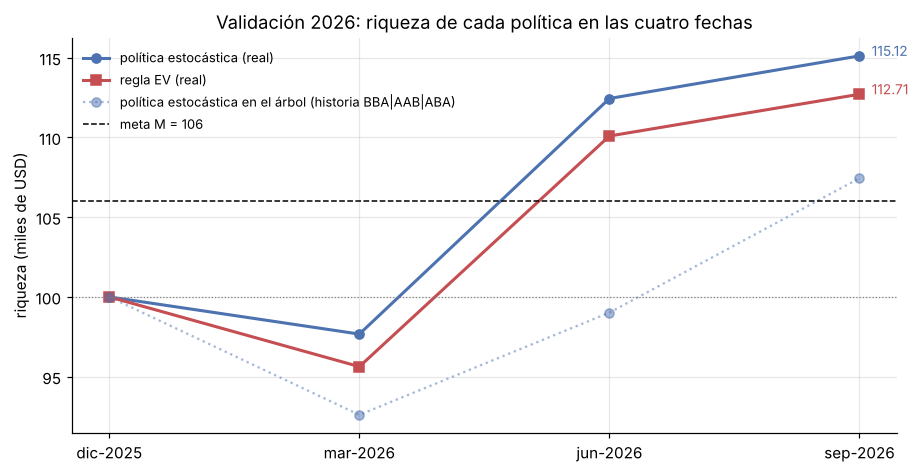

In [6]:
final = pd.DataFrame({"estocástica": final_sp, "regla EV": final_ev})
final["diferencia (EV − estocástica)"] = final["regla EV"] - final["estocástica"]
with pd.option_context("display.float_format", "{:.6f}".format):
    display(final)
print(f"Diferencia de costo realizado (EV − estocástica): {final.at['costo realizado', 'diferencia (EV − estocástica)']:.6f}")
print(f"Como referencia, en el árbol: VSS = EEV − RP = {ev_meta['VSS']:.6f} (cantidad distinta, no comparable 1 a 1).")

w_sp = [B_CAP] + chron_sp["V fin"].tolist()
w_ev = [B_CAP] + chron_ev["V fin"].tolist()
LEAVES_TREE = pd.read_csv(ROOT / sp_meta["leaves_csv"], keep_default_na=False, na_values=[""])
OBS_HIST = "|".join(Z_REAL[t] for t in (1, 2, 3))
tree_path = []
if not fb_sp:   # riqueza representativa del árbol a lo largo de la historia observada
    tree_path = [V_TREE[(1, 1)]] + [V_TREE[(t + 1, chron_sp.at[t + 1, "nodo k_t"])] for t in (1, 2)]
    tree_path.append(float(LEAVES_TREE.loc[LEAVES_TREE["history"] == OBS_HIST, "V4"].iloc[0]))
wealth = pd.DataFrame({"fecha": DATES, "estocástica": w_sp, "regla EV": w_ev}).set_index("fecha")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(wealth)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x_lab = ["dic-2025", "mar-2026", "jun-2026", "sep-2026"]
ax.plot(x_lab, w_sp, "o-", color="#4c72b0", lw=2, label="política estocástica (real)")
ax.plot(x_lab, w_ev, "s-", color="#c44e52", lw=2, label="regla EV (real)")
if tree_path:
    ax.plot(x_lab, tree_path, "o:", color="#4c72b0", alpha=0.5,
            label=f"política estocástica en el árbol (historia {OBS_HIST})")
ax.axhline(M_GOAL, color="black", ls="--", lw=1, label=f"meta M = {M_GOAL:g}")
ax.axhline(B_CAP, color="gray", ls=":", lw=0.8)
for xs_, ys_, col in [(x_lab, w_sp, "#4c72b0"), (x_lab, w_ev, "#c44e52")]:
    ax.annotate(f"{ys_[-1]:.2f}", (xs_[-1], ys_[-1]), textcoords="offset points", xytext=(8, 0), color=col, fontsize=9)
ax.set_ylabel("riqueza (miles de USD)")
ax.set_title("Validación 2026: riqueza de cada política en las cuatro fechas")
ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "06_validation_wealth.png"); plt.show()

## 6. Composición aplicada en cada trimestre

Las barras muestran las proporciones que cada política aplicó al comenzar cada trimestre. En la política estocástica cambian según la historia observada; en la regla EV son fijas por construcción.

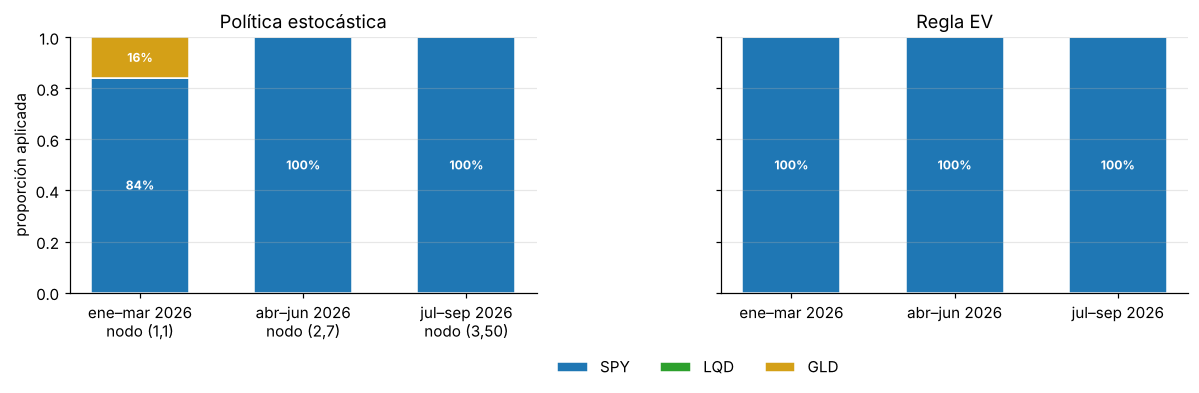

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (chron, name) in zip(axes, [(chron_sp, "Política estocástica"), (chron_ev, "Regla EV")]):
    labels = [f"{QLABEL[t]}\n" + (f"nodo ({t},{chron.at[t, 'nodo k_t']})" if name.startswith("Pol") else "")
              for t in chron.index]
    bottom = np.zeros(len(chron))
    for tk in TICKERS:
        v = chron[f"prop {tk}"].to_numpy()
        ax.bar(labels, v, bottom=bottom, color=ASSET_COLORS[tk], label=tk, edgecolor="white", width=0.6)
        for i, (vi, b0) in enumerate(zip(v, bottom)):
            if vi >= 0.06:
                ax.text(i, b0 + vi / 2, f"{vi:.0%}", ha="center", va="center", color="white", fontsize=8, weight="bold")
        bottom += v
    ax.set_title(name); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("proporción aplicada")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(-0.05, -0.2), ncol=3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "06_validation_proportions.png", bbox_inches="tight"); plt.show()

## 7. Insumos para las conclusiones 

**Riqueza del árbol frente a la observada:** En el árbol, cada rama aplica el factor promedio $\hat R(u)$ de su grupo; en 2026 se aplican los factores reales. Aunque la terna coincida, el rendimiento real rara vez es igual al promedio del grupo, y la diferencia se acumula trimestre a trimestre. La tabla compara, para cada trimestre, el rendimiento real con el promedio del grupo en que se clasificó y con el rango observado en ese grupo durante la calibración (2010–2025).

**Promedios de grupo frente a rendimientos históricos:** Si un rendimiento de 2026 queda lejos del promedio del grupo pero dentro de su rango histórico, muestra la variabilidad que el árbol elimina al resumir cada grupo por su media.

In [8]:
cal_ret = pd.read_csv(ROOT / "results" / "tables" / "01_quarterly_returns_calibration.csv",
                      keep_default_na=False, na_values=[""])
rows = []
for tau in (1, 2, 3):
    z = Z_REAL[tau]
    grp = cal_ret[cal_ret["state"] == z]
    for i, tk in enumerate(TICKERS):
        rows.append({"τ": tau, "terna": z, "activo": tk, "n en calibración": len(grp),
                     "r̃ real 2026 (%)": 100 * r_REAL[tau][i],
                     "R̂(u) − 1 del grupo (%)": 100 * (R_HAT[z][i] - 1) if z in R_HAT else np.nan,
                     "mín. histórico del grupo (%)": 100 * grp[f"r_{tk}"].min() if len(grp) else np.nan,
                     "máx. histórico del grupo (%)": 100 * grp[f"r_{tk}"].max() if len(grp) else np.nan})
gcmp = pd.DataFrame(rows).set_index(["τ", "terna", "activo"])
gcmp["real − promedio (pp)"] = gcmp["r̃ real 2026 (%)"] - gcmp["R̂(u) − 1 del grupo (%)"]
gcmp["dentro del rango histórico"] = ((gcmp["r̃ real 2026 (%)"] >= gcmp["mín. histórico del grupo (%)"]) &
                                      (gcmp["r̃ real 2026 (%)"] <= gcmp["máx. histórico del grupo (%)"]))
with pd.option_context("display.float_format", "{:.3f}".format):
    display(gcmp)

if not fb_sp:
    leaf_hist = OBS_HIST
    leaf = LEAVES_TREE[LEAVES_TREE["history"] == leaf_hist].iloc[0]
    tv = pd.DataFrame({"fecha": DATES,
                       "nodo": [f"({t},{chron_sp.at[t, 'nodo k_t']})" for t in (1, 2, 3)] + [f"(4,{int(leaf['k'])})"],
                       "riqueza en el árbol": tree_path, "riqueza real": w_sp})
    tv["diferencia (real − árbol)"] = tv["riqueza real"] - tv["riqueza en el árbol"]
    print(f"Trayectoria observada en el árbol: hoja con historia {leaf_hist} "
          f"(p⁴ = {leaf['p_cum']:.6f}, riqueza del árbol {leaf['V4']:.4f}, costo del árbol {leaf['cost']:.4f}); "
          f"riqueza real {w_sp[-1]:.4f}, costo real {final_sp['costo realizado']:.4f}.")
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(tv.set_index("fecha"))

unused = {name: [tk for tk in TICKERS if (ch[f"x {tk}"] <= 1e-9).all()] for name, ch
          in [("estocástica", chron_sp), ("EV", chron_ev)]}
print("Activos sin inversión en los tres trimestres:", unused)

n en calibración  r̃ real 2026 (%)  R̂(u) − 1 del grupo (%)  mín. histórico del grupo (%)  máx. histórico del grupo (%)  real − promedio (pp)  \
τ terna activo                                                                                                                                                  
1 BBA   SPY                    4            -4.371                   -9.647                       -19.448                        -0.995                 5.277   
        LQD                    4            -0.381                   -3.708                        -8.377                        -0.586                 3.327   
        GLD                    4             8.574                    4.633                         1.731                         7.529                 3.941   
2 AAB   SPY                    6            15.123                    6.924                         3.071                        11.618                 8.200   
        LQD                    6             1.261                    2.028                         1.154                         3.030                -0.767   
        GLD                    6           -14.388                   -3.620                        -9.409                        -0.590               -10.768   
3 ABA   SPY                    3             2.377                    8.510                         4.379                        10.761                -6.133   
        LQD                    3            -5.184                   -1.328                        -2.612                        -0.511                -3.856   
        GLD                    3             3.382                    6.859                         4.516                         8.451                -3.477   

                dentro del rango histórico  
τ terna activo                              
1 BBA   SPY                           True  
        LQD                          False  
        GLD                          False  
2 AAB   SPY                          False  
        LQD                           True  
        GLD                          False  
3 ABA   SPY                          False  
        LQD                          False  
        GLD                          False

Trayectoria observada en el árbol: hoja con historia BBA|AAB|ABA (p⁴ = 0.000275, riqueza del árbol 107.4431, costo del árbol -1.4431); riqueza real 115.1156, costo real -9.1156.


,nodo,riqueza en el árbol,riqueza real,diferencia (real − árbol)
fecha,,,,
2025-12-31,"(1,1)",100.0000,100.0000,0.0000
2026-03-31,"(2,7)",92.6050,97.6711,5.0661
2026-06-30,"(3,50)",99.0167,112.4424,13.4257
2026-09-30,"(4,395)",107.4431,115.1156,7.6725


Activos sin inversión en los tres trimestres: {'estocástica': ['LQD'], 'EV': ['LQD', 'GLD']}


## 8. Alcance de la validación

La validación contiene **una sola trayectoria** de nueve meses. Permite comprobar que la implementación funciona sobre datos reales y describir lo que ocurrió en ese período. No basta para concluir que una política es superior en general, ni para estimar una probabilidad confiable de éxito, ni para afirmar significancia estadística. Los tres trimestres tampoco son tres repeticiones independientes del experimento completo: forman una única realización de la trayectoria de nueve meses. Las cantidades que comparan las políticas en sentido esperado son las del árbol (RP, EEV y VSS, notebook 05), y aun esas dependen de los supuestos de la calibración: ocho grupos resumidos por su media e independencia temporal entre trimestres.

## 9. Exportación

In [9]:
chron_sp.to_csv(VAL_OUT / "stochastic_chronology.csv", float_format="%.12g")
chron_ev.to_csv(VAL_OUT / "ev_chronology.csv", float_format="%.12g")
final.to_csv(VAL_OUT / "final_comparison.csv", float_format="%.12g")
wealth.to_csv(VAL_OUT / "wealth_four_dates.csv", float_format="%.12g")
obs.to_csv(VAL_OUT / "observed_returns_2026.csv", float_format="%.12g")
gcmp.to_csv(VAL_OUT / "group_mean_vs_realized.csv", float_format="%.12g")
summary = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "policies_verified_at_utc": verified_at.isoformat(timespec="seconds"),
    "stochastic_policy_sha256": sha256_of(sp_meta_path), "ev_policy_sha256": sha256_of(ev_path),
    "validation_csv_sha256": val_meta["csv_sha256"],
    "observed_states": Z_REAL, "observed_history": "|".join(Z_REAL[t] for t in (1, 2, 3)),
    "fallback_activated": fb_sp, "goal_tolerance_thousands_usd": GOAL_TOL,
    "stochastic": final_sp, "ev": final_ev,
    "realized_cost_difference_ev_minus_stochastic": final_ev["costo realizado"] - final_sp["costo realizado"],
    "note": "Una sola trayectoria: no es el VSS ni permite conclusiones generales (sección 5.4).",
}
(VAL_OUT / "validation_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float),
                                                 encoding="utf-8")
print("Guardado:")
for p in sorted(VAL_OUT.iterdir()):
    print("  ", p.relative_to(ROOT))
for f in ["06_validation_wealth.png", "06_validation_proportions.png"]:
    print("  ", (FIGURES_DIR / f).relative_to(ROOT))

Guardado:
   results/validation/ev_chronology.csv
   results/validation/final_comparison.csv
   results/validation/group_mean_vs_realized.csv
   results/validation/observed_returns_2026.csv
   results/validation/stochastic_chronology.csv
   results/validation/validation_summary.json
   results/validation/wealth_four_dates.csv
   results/figures/06_validation_wealth.png
   results/figures/06_validation_proportions.png
